# load the data

In [1]:
import pandas as pd
import numpy as np

In [2]:
df=pd.read_csv("powerplant_data.csv")

In [3]:
df.head()

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


In [4]:
#AT=TEMPERATURE
#V=VACUUM
#AP=PRESSURE
#RH=HUMIDITY
#PE=PREDUCED ENERGY

In [5]:
df.isnull().sum()

AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

In [6]:
x=df.drop("PE",axis=1)
y=df["PE"]

In [7]:
#split data
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [8]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.transform(x_test)

# convert into pytorch tensors

In [9]:
import torch
import torch.nn as nn

x_train_tensor=torch.tensor(x_train_scaled,dtype=torch.float32)
x_test_tensor=torch.tensor(x_test_scaled,dtype=torch.float32)

y_train_tensor=torch.tensor(y_train.values,dtype=torch.float32).view(-1,1)
y_test_tensor=torch.tensor(y_test.values,dtype=torch.float32).view(-1,1)
#we have y_train as pandas series not array so ve have to write x_trqain.values otherwise not needed
# we have .view() to vertical metrix 

In [10]:
from torch.utils.data import TensorDataset,DataLoader
train_dataset=TensorDataset(x_train_tensor,y_train_tensor)
test_dataset=TensorDataset(x_test_tensor,y_test_tensor)

In [11]:
train_loader=DataLoader(train_dataset,batch_size=32,shuffle=32)
test_loader=DataLoader(test_dataset,batch_size=32)

# build ann model

In [12]:
class ANN(nn.Module):
    def __init__(self):#create constructer
        super(ANN,self).__init__()#call constructer
        self.model=nn.Sequential(
            #1st hidden layer
            nn.Linear(x_train.shape[1],6),# we define how much ip and op will product
            nn.ReLU(),
    
            #2nd hidden layer
            nn.Linear(6,6),
            nn.ReLU(),
    
            #output layer
            nn.Linear(6,1),
        )
## forward propagation
    def forward(self,x):
        return self.model(x)

In [13]:
import torch.optim as optim
model=ANN()
# loss,optimizer
crietrion=nn.MSELoss() # loss func
optimizer=optim.Adam(model.parameters())#parameters like weight,bias ther is already available with nn so we dont initialize


# train the model

In [14]:
epochs=100 #define epoch
best_val_loss=float("inf") # to save model and inf stands for infinity
valid_lossess=[]
train_lossess=[] # we have initialize blank dictonary to store loss of every epoch
for epoch in range(epochs):
    model.train() #put in training mode
    running_loss=0.0 #save training loss for one epoch
    for xb,yb in train_loader: #train loader give every batch
        #xb=features of 1 batch
        #yb=labels of 1 batch
        optimizer.zero_grad() #it removers old grediants 
        outputs=model(xb) #predicted output of 1 batch
        loss=crietrion(outputs,yb) #calculate loss of pirticular batch
        loss.backward()#back prop. it compute gradients
        optimizer.step() #it update weights and bias
        running_loss+=loss.item() #loss is tensor value we convert it to python flot value
    epoch_train_loss=running_loss/len(train_loader) #len() is number of batches
    train_lossess.append(epoch_train_loss)

    #validation
    model.eval()
    running_val_loss=0.0
    with torch.no_grad(): # we tells no gradients compute
         for xb,yb in test_loader:
            outputs=model(xb)
            loss=crietrion(outputs,yb)
            running_val_loss+=loss
    epoch_val_loss=running_val_loss/len(test_loader) #len() is number of batches
    valid_lossess.append(epoch_val_loss)
    print(f"epoch${epoch+1}/{epochs}=>> training loss=#{epoch_train_loss}& val loss=${epoch_val_loss}")
    if epoch_val_loss<best_val_loss:
        best_val_loss=epoch_val_loss
        torch.save(model.state_dict(),"annregression.pt") #store weights and bias and save file
##at validation time there is no back prop so no need of gradient,optimizer


epoch$1/100=>> training loss=#206437.17799479168& val loss=$205071.828125
epoch$2/100=>> training loss=#201134.20338541668& val loss=$194139.359375
epoch$3/100=>> training loss=#181214.08541666667& val loss=$164537.9375
epoch$4/100=>> training loss=#142750.71575520834& val loss=$118850.4921875
epoch$5/100=>> training loss=#94602.63854166666& val loss=$71377.140625
epoch$6/100=>> training loss=#53053.47399088542& val loss=$37885.953125
epoch$7/100=>> training loss=#28914.018884277342& val loss=$22399.44921875
epoch$8/100=>> training loss=#19142.48924967448& val loss=$16576.376953125
epoch$9/100=>> training loss=#15127.341670735677& val loss=$13523.00390625
epoch$10/100=>> training loss=#12485.656233723957& val loss=$11168.423828125
epoch$11/100=>> training loss=#10317.167295328776& val loss=$9089.2236328125
epoch$12/100=>> training loss=#8269.040661621093& val loss=$7176.81201171875
epoch$13/100=>> training loss=#6438.594664510091& val loss=$5446.14794921875
epoch$14/100=>> training los

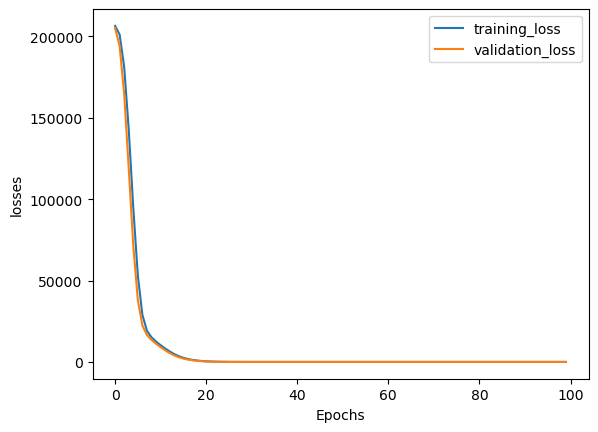

In [15]:
import matplotlib.pyplot as plt
loss_df=pd.DataFrame({
    "train_loss":train_lossess,
    "val_loss":valid_lossess
})
plt.plot(loss_df["train_loss"],label="training_loss")
plt.plot(loss_df["val_loss"],label="validation_loss")
plt.xlabel("Epochs")
plt.ylabel("losses")
plt.legend()

In [20]:
#loading best model
model.load_state_dict(torch.load("annregression.pt"))

<All keys matched successfully>

In [21]:
#evaluation
model.eval()
with torch.no_grad(): #we dont need compute gradient
    train_pred=model(x_train_tensor)
    test_pred=model(x_test_tensor)

    train_mse_loss=crietrion(train_pred,y_train_tensor)
    test_mse_loss=crietrion(test_pred,y_test_tensor)

print("training mse",train_mse_loss.item())
print("test mse",test_mse_loss.item())
    

training mse 21.039403915405273
test mse 19.406553268432617


In [22]:
from sklearn.metrics import r2_score
print("r2 score",r2_score(y_test,test_pred))

r2 score 0.9321790985057412


In [19]:
predict_df=pd.DataFrame(test_pred.numpy(),columns=["predicted values"])
actual_df=pd.DataFrame(y_test.values,columns=["actual values"])
pd.concat([predict_df,actual_df],axis=1)

,predicted values,actual values
0,435.205872,433.27
1,436.877930,438.16
2,461.483215,458.42
3,476.653687,480.82
4,435.238159,441.41
...,...,...
1909,451.446655,456.70
1910,431.504791,438.04
1911,467.982086,467.80
1912,430.941864,437.14
